# 23. One Gaussian between three photographs

[Course plan](../../README.md)

The orange splat starts on the left and ends on the right. Joining its two centers with a straight line makes a perfectly smooth animation. A third exposure halfway through reveals the miss. The silhouette is changing too. Center motion and shape can be followed separately.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dynamic_motion.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import dynamic_motion as motion
from dynamic_motion_demos import motion_figure, motion_lab
lang = 'en'

## Two marks already determine a line

The camera is the one from the previous experiment. The known depth is 4 m, the central column $u_0=48$ px and the focal length $f=80$ px. At 0 and 2 seconds the orange center appears at columns 38 and 62. In the first exposure the offset is $38-48=-10$ px. Dividing by 80 gives a slope of $-0.125$, and multiplying by 4 m gives a position of $-0.5$ m. For the second exposure, $(62-48)\cdot4/80=0.7$ m. The two images have yielded two spatial measurements.

The splat went from $-0.5$ to $0.7$ m in 2 s. The difference is $0.7-(-0.5)=1.2$ m, so the average velocity was $1.2/2=0.6$ m/s. At that constant velocity the center would reach $-0.5+0.6=0.1$ m after one second. The dashed line joins the observations. Green shows the reference motion withheld from the fit. A vertical mark in the image shows its projected center.

In [2]:
display(motion_lab(23, lang))

In [3]:
pixels = np.array([38., 62.])
positions = (pixels - motion.U0) * motion.DEPTH / motion.F
v = (positions[1] - positions[0]) / 2
print('x (m)', positions, '  v (m/s)', v, '  x(1) (m)', round(positions[0] + v, 3))

x (m) [-0.5  0.7]   v (m/s) 0.6   x(1) (m) 0.1


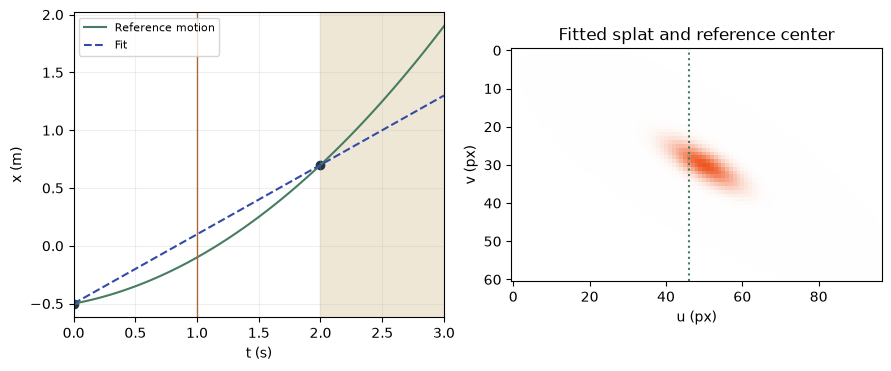

In [4]:
fig = motion_figure(23, lang)
plt.show()

## One more exposure bends the path

Halfway through the interval the camera actually sees column 46. The measured position is $(46-48)\cdot4/80=-0.1$ m. The straight line missed by $0.2$ m or $80\cdot0.2/4=4$ pixels. How could a curve correct that miss while leaving both measured endpoints in place?

The number of elapsed seconds is $h=t/(1\,\mathrm{s})$. The units cancel in this ratio. The product $g=h(2-h)$ vanishes at $h=0$ and $h=2$, but equals one at $h=1$. Multiplying it by the middle measurement's displacement from the line puts a correction exactly where it is needed. Here $l(t)$ denotes the line and $x_1$ the middle position measured in metres.

$$
\begin{aligned}
l(t)&=-0.5+0.6h\quad\text{(m)},\\
x_1-l(1\,\mathrm{s})&=-0.1-0.1=-0.2\quad\text{(m)},\\
x_{\mathrm{fit}}(t)&=l(t)+(x_1-l(1\,\mathrm{s}))\,h(2-h).
\end{aligned}
$$

At half a second the line gives $-0.5+0.3=-0.2$ m. The correction has weight $0.5(2-0.5)=0.75$. Together they give $-0.2-0.2\cdot0.75=-0.35$ m, or column 41. This intermediate exposure tests both models at a time neither used for fitting.

In [5]:
for t in [0, .5, 1, 2, 3]:
    truth = motion.true_x(t)
    for third in [False, True]:
        fitted = motion.fit_path(t, middle=third)
        print(f"t={t:.1f} s   n={2+int(third)}   x={fitted:+.3f} m   |Δu|={20*abs(fitted-truth):.2f} px")

t=0.0 s   n=2   x=-0.500 m   |Δu|=0.00 px
t=0.0 s   n=3   x=-0.500 m   |Δu|=0.00 px
t=0.5 s   n=2   x=-0.200 m   |Δu|=3.00 px
t=0.5 s   n=3   x=-0.350 m   |Δu|=0.00 px
t=1.0 s   n=2   x=+0.100 m   |Δu|=4.00 px
t=1.0 s   n=3   x=-0.100 m   |Δu|=0.00 px
t=2.0 s   n=2   x=+0.700 m   |Δu|=0.00 px
t=2.0 s   n=3   x=+0.700 m   |Δu|=0.00 px
t=3.0 s   n=2   x=+1.300 m   |Δu|=12.00 px
t=3.0 s   n=3   x=+1.900 m   |Δu|=0.00 px


## What rotates inside the splat

The splat stays at $z=4$ m and $y=0$. Its long scale starts at 0.24 m and grows by 0.08 m per second. After one second $s_x=0.24+0.08=0.32$ m. The transverse scale holds at 0.11 m and the depth scale at 0.08 m. All three stay positive throughout the displayed interval from 0 to 3 s. The long axis turns by $30^\circ$ per second around the depth axis. The camera looks along that axis and screen y points down, so the turn appears clockwise.

The renderer from lesson 14 takes four rotation components. For an axis of $(0,0,1)$ the angle is halved. Half of $30^\circ$ is $15^\circ$. The first component is $\cos(15^\circ)\approx0.966$, the last is $\sin(15^\circ)\approx0.259$ and the other two are zero. Scale and orientation follow prescribed paths here. The measured columns are used to recover the center trajectory.

In [6]:
spot = motion.trajectory_splat(1, motion.fit_path(1, middle=True))
for key in ['center', 'scales', 'rotation']:
    print(key, np.round(spot[key], 4))

center [-0.1  0.   4. ]
scales [0.32 0.11 0.08]
rotation [0.9659 0.     0.     0.2588]


## Beyond the last exposure

Between the observations, up to 2 s, the curve interpolates. Past the last observation it extrapolates. The synthetic reference follows a line plus $a\,t(t-2\,\mathrm{s})$, where $a$ has units of m/s². At $a=0.2$ three exact observations determine this parabola completely. A real splat might stop after the last exposure even if a parabola passed through all three observations perfectly.

If the middle observation is shifted by $+0.1$ m, its error is multiplied by $h(2-h)$. At 0.5 s that gives $+0.075$ m. At 3 s it gives $0.1\cdot3\cdot(-1)=-0.3$ m. Moving the middle mark right sent the prediction left and tripled the error. The gap between the splat and the green mark in the next image shows the shift.

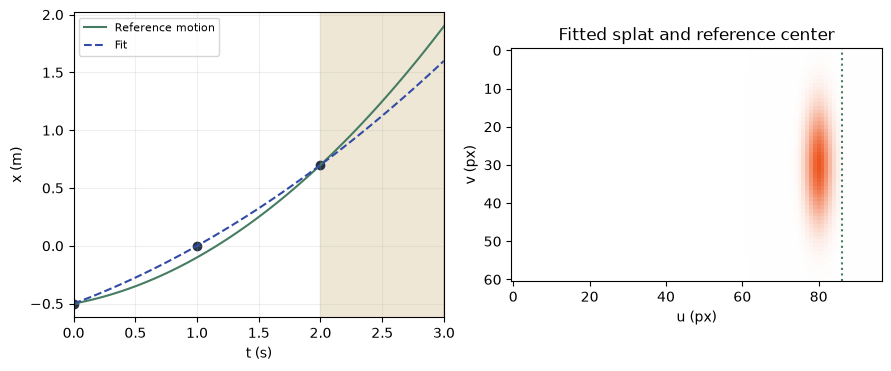

In [7]:
fig = motion_figure(23, lang, time=3, middle=True, noise=.1)
plt.show()

**A change of numbers.** The actual motion is linear, but the middle observation is shifted by $+0.1$ m. Which fit is closer at 3 s?

<details><summary>Worked answer</summary>

The line through the two accurate endpoints continues the true path. The parabola passes through all three measurements and misses by 0.3 m to the left. At 20 pixels per metre that is 6 pixels. Extra observations help when their uncertainty is also accounted for. This fit has to pass through even the corrupted observation.

</details>